In [ ]:
import pandas as pd
import re

In [5]:
df = pd.read_csv('gojek_reviews.csv')

print(df.shape)

df_sample = df.sample(
    n=5000,
    random_state=42
).copy()

print("Jumlah data awal:", len(df))
print("Jumlah data sampel:", len(df_sample))

df_sample.head()

df_sample.to_csv(
    'gojek_reviews_5000.csv',
    index=False
)

(225002, 5)
Jumlah data awal: 225002
Jumlah data sampel: 5000


In [7]:
print(df_sample['score'].value_counts().sort_index())

print(df_sample.isnull().sum())
print("Jumlah duplikat:", df_sample.duplicated(subset=['content']).sum())

score
1     977
2     189
3     226
4     313
5    3295
Name: count, dtype: int64
userName      0
content       0
score         0
at            0
appVersion    0
dtype: int64
Jumlah duplikat: 1345


In [8]:
duplicates = df_sample[
    df_sample.duplicated(subset=['content'], keep=False)
].sort_values('content')

display(duplicates[['content', 'score']].head(20))

,content,score
120373,Alhamdulillah,5
111615,Alhamdulillah,5
27739,Alhamdulillah,5
52039,Amanah,5
127554,Amanah,4
110323,Aplikasi bagus,4
214234,Aplikasi bagus,5
39176,Aplikasi keren,5
200310,Aplikasi keren,5
37371,Aplikasi top,5


In [10]:
print("Total data:", len(df_sample))
print("Review unik:", df_sample['content'].nunique())

rating_check = (
    df_sample.groupby('content')['score']
    .nunique()
)

print("Review dengan rating berbeda:",
      (rating_check > 1).sum())

print("Review dengan rating sama:",
      (rating_check == 1).sum())

Total data: 5000
Review unik: 3655
Review dengan rating berbeda: 53
Review dengan rating sama: 3602


In [11]:
df_dedup = (
    df_sample.groupby('content', as_index=False)
    .agg({
        'score': 'median'
    })
)

df_dedup['score'] = df_dedup['score'].round().astype(int)

print("Jumlah data awal:", len(df_sample))
print("Jumlah setelah deduplikasi:", len(df_dedup))

Jumlah data awal: 5000
Jumlah setelah deduplikasi: 3655


In [12]:
def labeling(score):
    if score <= 2:
        return -1
    elif score == 3:
        return 0
    else:
        return 1

df_dedup['sentiment'] = df_dedup['score'].apply(labeling)

print(df_dedup['sentiment'].value_counts().sort_index())

sentiment
-1    1153
 0     213
 1    2289
Name: count, dtype: int64


In [13]:
print(
    df_dedup['sentiment']
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

sentiment
 1    62.63
-1    31.55
 0     5.83
Name: proportion, dtype: float64


In [55]:
print(df_dedup.isnull().sum())

print((df_dedup['content'].astype(str).str.strip() == '').sum())

print(df_dedup.duplicated(subset=['content']).sum())

df_dedup = df_dedup[
    df_dedup['content'].notna() &
    (df_dedup['content'].str.strip() != '')
].copy()

df_dedup.reset_index(drop=True, inplace=True)

print("Abis apus review kosong", len(df_dedup))

print(df_dedup['sentiment'].value_counts())

content               0
score                 0
sentiment             0
clean_content         0
normalized_content    0
final_text            0
dtype: int64
0
0
Abis apus review kosong 3653
sentiment
 1    2288
-1    1152
 0     213
Name: count, dtype: int64


In [58]:
def clean_text(text):
    text = str(text).lower()

    text = re.sub(r'https?://\S+|www\.\S+', '', text)

    text = re.sub(r'@[A-Za-z0-9_]+', '', text)

    text = re.sub(r'#(\w+)', r'\1', text)

    text = re.sub(r'\d+', ' ', text)

    text = re.sub(r'[^a-zA-Z\s]', ' ', text)

    text = re.sub(r'\s+', ' ', text).strip()

    return text

df_dedup['clean_content'] = df_dedup['content'].apply(clean_text)
sample = df_dedup.sample(10, random_state=42)

for original, cleaned in zip(
    sample['content'],
    sample['clean_content']
):
    print("Original:", original)
    print("Cleaned :", cleaned)
    print("-" * 50)


Original: Kereeeen selalu dpt diskon hehe
Cleaned : kereeeen selalu dpt diskon hehe
--------------------------------------------------
Original: Mantappppp
Cleaned : mantappppp
--------------------------------------------------
Original: Aplikasi sampah ram 6 GB suka tidak respon aplikasi saya diinstal sedikit padahal cache udah dikosonginINTERNETPUN SANGAT LANCAR saya coba nonton YOUTUBE kualitas 1080 itu LANCAR TAPI APKNYA masih tetap begitu  Katanya pegawainya pengalaman 50tahun masih muda dan IPK 1000 tapi order kang jek sering eror jadi mempersulit untuk komunikasi kang ojek saat menentukan lokasi penjemputan Update dong bisanya tapi tidak berguna dan ngaruh sama sekali
Cleaned : aplikasi sampah ram gb suka tidak respon aplikasi saya diinstal sedikit padahal cache udah dikosongininternetpun sangat lancar saya coba nonton youtube kualitas itu lancar tapi apknya masih tetap begitu katanya pegawainya pengalaman tahun masih muda dan ipk tapi order kang jek sering eror jadi mempersulit

In [24]:
from collections import Counter

all_words = ' '.join(df_dedup['clean_content']).split()

word_freq = Counter(all_words)

word_freq.most_common(50)

[('gojek', 710),
 ('saya', 703),
 ('di', 689),
 ('dan', 548),
 ('nya', 494),
 ('bisa', 467),
 ('driver', 437),
 ('aplikasi', 437),
 ('ada', 404),
 ('sangat', 372),
 ('ini', 350),
 ('yg', 337),
 ('tidak', 320),
 ('ga', 295),
 ('gak', 274),
 ('gopay', 269),
 ('bagus', 254),
 ('lagi', 252),
 ('membantu', 250),
 ('yang', 240),
 ('mau', 233),
 ('ke', 216),
 ('banget', 211),
 ('padahal', 201),
 ('lama', 199),
 ('tapi', 188),
 ('makin', 186),
 ('aja', 183),
 ('banyak', 175),
 ('promo', 169),
 ('pake', 168),
 ('untuk', 168),
 ('kenapa', 167),
 ('ya', 166),
 ('lebih', 165),
 ('udah', 165),
 ('sudah', 162),
 ('malah', 149),
 ('selalu', 146),
 ('tolong', 144),
 ('sekali', 143),
 ('jadi', 142),
 ('juga', 139),
 ('sama', 138),
 ('buat', 136),
 ('terus', 134),
 ('sekarang', 131),
 ('gk', 126),
 ('dari', 126),
 ('mahal', 124)]

In [29]:
norm = {
    'yg': 'yang',
    'ga': 'tidak',
    'gak': 'tidak',
    'gk': 'tidak',
    'udah': 'sudah',
    'aja': 'saja',
    'pake': 'pakai',
    'banget': 'sangat',
    'dpt': 'dapat',
    'udh': 'sudah',
    'gabisa': 'tidak bisa',
    'gakbisa': 'tidak bisa',
    'gkbisa': 'tidak bisa',
    'pokokny': 'pokoknya',
    'apk': 'aplikasi',
    'dahlah': 'sudahlah',
    'dptnya': 'dapatnya',
    'eror': 'error',
    'corp': 'perusahaan',
    'dgn': 'dengan',
    'utk': 'untuk',
    'tdk': 'tidak',
    'bgt': 'sangat',
}
norm.pop('banget', None)

df_dedup['normalized_content'] = (
    df_dedup['clean_content'].apply(normalize_text)
)

def normalize_text(text):
    words = text.split()

    normalized_words = [
        norm.get(word, word)
        for word in words
    ]

    return ' '.join(normalized_words)

df_dedup['normalized_content'] = (
    df_dedup['clean_content'].apply(normalize_text)
)

sample = df_dedup.sample(10, random_state=42)

for original, normalized in zip(
    sample['clean_content'],
    sample['normalized_content']
):
    print("Sebelum:", original)
    print("Sesudah:", normalized)
    print("-" * 50)

Sebelum: kereeeen selalu dpt diskon hehe
Sesudah: kereeeen selalu dapat diskon hehe
--------------------------------------------------
Sebelum: mantappppp
Sesudah: mantappppp
--------------------------------------------------
Sebelum: aplikasi sampah ram gb suka tidak respon aplikasi saya diinstal sedikit padahal cache udah dikosongininternetpun sangat lancar saya coba nonton youtube kualitas itu lancar tapi apknya masih tetap begitu katanya pegawainya pengalaman tahun masih muda dan ipk tapi order kang jek sering eror jadi mempersulit untuk komunikasi kang ojek saat menentukan lokasi penjemputan update dong bisanya tapi tidak berguna dan ngaruh sama sekali
Sesudah: aplikasi sampah ram gb suka tidak respon aplikasi saya diinstal sedikit padahal cache sudah dikosongininternetpun sangat lancar saya coba nonton youtube kualitas itu lancar tapi apknya masih tetap begitu katanya pegawainya pengalaman tahun masih muda dan ipk tapi order kang jek sering error jadi mempersulit untuk komunikasi

In [35]:

from Sastrawi.StopWordRemover.StopWordRemoverFactory import StopWordRemoverFactory

factory = StopWordRemoverFactory()
stopwords = set(factory.get_stop_words())

negation_words = {'tidak', 'bukan', 'belum', 'jangan', 'kurang'}

stopwords = stopwords - negation_words

def remove_stopwords(text):
    words = text.split()
    filtered_words = [
        word for word in words
        if word not in stopwords
    ]
    return ' '.join(filtered_words)

negation_words = {
    'tidak', 'bukan', 'belum', 'jangan', 'kurang',
    'nggak', 'enggak', 'gak', 'ga', 'gk',
    'tak', 'ndak'
}

stopwords = stopwords - negation_words

df_dedup['final_text'] = (
    df_dedup['normalized_content'].apply(remove_stopwords)
)

print(df_dedup[
    df_dedup['normalized_content'].str.contains(
        r'\bnggak\b', na=False
    )
][['normalized_content', 'final_text']].head(10))

                                     normalized_content  \
4                     respon drivernya nggak secepat ub   
235      aplikasi saya hilang terus nggak bisa di akses   
349   bagus banget tapi mulohon perbaiki bagian chat...   
369   bagus hanya saja banyak lokasi yang tidak terd...   
717             driver nya sibuk terus nggak masuk akal   
834   gatel lah pakai tambaan biaya segala lah sudah...   
846   gimana ceritanya ongkir gofood bisa naik secar...   
1009  gopay kenapa ya jadi error saya top up game da...   
1045  hai gojeksampai kapan promo gofood pilih saja ...   
1275  kenapa pajak pakai gopay paylater dari findaya...   

                                             final_text  
4                     respon drivernya nggak secepat ub  
235                   aplikasi hilang terus nggak akses  
349   bagus banget mulohon perbaiki bagian chat nya ...  
369   bagus banyak lokasi tidak terdeteksi kadang pa...  
717             driver nya sibuk terus nggak masuk akal  
83

In [38]:
from sklearn.feature_extraction.text import TfidfVectorizer

tfidf = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 2)
)

X = tfidf.fit_transform(df_dedup['final_text'])
y = df_dedup['sentiment']

print("Ukuran matriks TF-IDF:", X.shape)
print("Jumlah data:", len(y))

Ukuran matriks TF-IDF: (3653, 5000)
Jumlah data: 3653


In [39]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)
print("Data training:", X_train.shape)
print("Data testing:", X_test.shape)

print("\nDistribusi training:")
print(y_train.value_counts())

print("\nDistribusi testing:")
print(y_test.value_counts())

Data training: (2922, 5000)
Data testing: (731, 5000)

Distribusi training:
sentiment
 1    1830
-1     922
 0     170
Name: count, dtype: int64

Distribusi testing:
sentiment
 1    458
-1    230
 0     43
Name: count, dtype: int64


In [41]:
from sklearn.naive_bayes import MultinomialNB

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

nb_model = MultinomialNB()

nb_model.fit(X_train, y_train)
y_pred_nb = nb_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb, zero_division=0))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Accuracy: 0.813953488372093

Classification Report:
              precision    recall  f1-score   support

          -1       0.74      0.76      0.75       230
           0       0.00      0.00      0.00        43
           1       0.85      0.92      0.88       458

    accuracy                           0.81       731
   macro avg       0.53      0.56      0.54       731
weighted avg       0.76      0.81      0.79       731


Confusion Matrix:
[[174   0  56]
 [ 25   0  18]
 [ 37   0 421]]


In [42]:
from sklearn.linear_model import LogisticRegression

lr_model = LogisticRegression(
    max_iter=1000,
    class_weight='balanced',
    random_state=42
)

lr_model.fit(X_train, y_train)

y_pred_lr = lr_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred_lr))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred_lr, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_lr))

Accuracy: 0.7838577291381669

Classification Report:
              precision    recall  f1-score   support

          -1       0.72      0.75      0.74       230
           0       0.13      0.16      0.14        43
           1       0.90      0.86      0.88       458

    accuracy                           0.78       731
   macro avg       0.58      0.59      0.59       731
weighted avg       0.80      0.78      0.79       731


Confusion Matrix:
[[173  26  31]
 [ 22   7  14]
 [ 44  21 393]]


In [44]:
lr_model3 = LogisticRegression(
    max_iter=2000,
    C=2,
    class_weight='balanced',
    random_state=42
)

lr_model3.fit(X_train, y_train)

y_pred_lr3 = lr_model3.predict(X_test)

print(classification_report(
    y_test, y_pred_lr3, zero_division=0
))

              precision    recall  f1-score   support

          -1       0.74      0.77      0.75       230
           0       0.11      0.12      0.11        43
           1       0.90      0.88      0.89       458

    accuracy                           0.80       731
   macro avg       0.58      0.59      0.58       731
weighted avg       0.80      0.80      0.80       731



In [45]:
tfidf_uni = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1),
    sublinear_tf=True
)

X_uni = tfidf_uni.fit_transform(df_dedup['final_text'])

X_train_uni, X_test_uni, y_train_uni, y_test_uni = train_test_split(
    X_uni,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

lr_uni = LogisticRegression(
    max_iter=2000,
    C=0.5,
    class_weight='balanced',
    random_state=42
)

lr_uni.fit(X_train_uni, y_train_uni)

y_pred_uni = lr_uni.predict(X_test_uni)

print(classification_report(
    y_test_uni, y_pred_uni, zero_division=0
))

              precision    recall  f1-score   support

          -1       0.73      0.73      0.73       230
           0       0.18      0.28      0.22        43
           1       0.90      0.84      0.87       458

    accuracy                           0.78       731
   macro avg       0.60      0.62      0.61       731
weighted avg       0.80      0.78      0.79       731



In [46]:
from sklearn.pipeline import Pipeline

X_text = df_dedup['final_text']
y = df_dedup['sentiment']

X_train_text, X_test_text, y_train, y_test = train_test_split(
    X_text,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

lr_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 1),
        sublinear_tf=True
    )),
    ('model', LogisticRegression(
        max_iter=2000,
        C=0.5,
        class_weight='balanced',
        random_state=42
    ))
])

lr_pipeline.fit(X_train_text, y_train)

y_pred = lr_pipeline.predict(X_test_text)

print(classification_report(
    y_test, y_pred, zero_division=0
))

              precision    recall  f1-score   support

          -1       0.73      0.75      0.74       230
           0       0.19      0.35      0.24        43
           1       0.92      0.83      0.87       458

    accuracy                           0.78       731
   macro avg       0.61      0.64      0.62       731
weighted avg       0.82      0.78      0.79       731



In [47]:
nb_pipeline = Pipeline([
    ('tfidf', TfidfVectorizer(
        max_features=5000,
        ngram_range=(1, 1),
        sublinear_tf=True
    )),
    ('model', MultinomialNB())
])

nb_pipeline.fit(X_train_text, y_train)

y_pred_nb = nb_pipeline.predict(X_test_text)

print(classification_report(
    y_test, y_pred_nb, zero_division=0
))

              precision    recall  f1-score   support

          -1       0.73      0.77      0.75       230
           0       0.00      0.00      0.00        43
           1       0.86      0.92      0.89       458

    accuracy                           0.82       731
   macro avg       0.53      0.56      0.55       731
weighted avg       0.77      0.82      0.79       731



In [48]:
from sklearn.model_selection import GridSearchCV

param_grid = {
    'model__C': [0.1, 0.5, 1, 2, 5],
    'tfidf__max_features': [3000, 5000, 7000]
}

grid_search = GridSearchCV(
    lr_pipeline,
    param_grid,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    verbose=1
)

grid_search.fit(X_train_text, y_train)

print("Parameter terbaik:")
print(grid_search.best_params_)

print("\nMacro F1 terbaik:")
print(grid_search.best_score_)

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Parameter terbaik:
{'model__C': 0.5, 'tfidf__max_features': 5000}

Macro F1 terbaik:
0.6298045379843936


In [49]:
best_model = grid_search.best_estimator_

y_pred_best = best_model.predict(X_test_text)

print("Accuracy:",
      accuracy_score(y_test, y_pred_best))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred_best,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_best))

Accuracy: 0.7756497948016415

Classification Report:
              precision    recall  f1-score   support

          -1       0.73      0.75      0.74       230
           0       0.19      0.35      0.24        43
           1       0.92      0.83      0.87       458

    accuracy                           0.78       731
   macro avg       0.61      0.64      0.62       731
weighted avg       0.82      0.78      0.79       731


Confusion Matrix:
[[172  33  25]
 [ 19  15   9]
 [ 45  33 380]]


In [51]:
from imblearn.over_sampling import RandomOverSampler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression

tfidf_ros = TfidfVectorizer(
    max_features=5000,
    ngram_range=(1, 1),
    sublinear_tf=True
)

X_train_tfidf = tfidf_ros.fit_transform(X_train_text)
X_test_tfidf = tfidf_ros.transform(X_test_text)

ros = RandomOverSampler(random_state=42)

X_train_ros, y_train_ros = ros.fit_resample(
    X_train_tfidf,
    y_train
)

lr_ros = LogisticRegression(
    max_iter=2000,
    C=0.5,
    random_state=42
)

lr_ros.fit(X_train_ros, y_train_ros)

y_pred_ros = lr_ros.predict(X_test_tfidf)

print(classification_report(
    y_test,
    y_pred_ros,
    zero_division=0
))

              precision    recall  f1-score   support

          -1       0.73      0.74      0.73       230
           0       0.17      0.30      0.22        43
           1       0.92      0.84      0.88       458

    accuracy                           0.78       731
   macro avg       0.60      0.63      0.61       731
weighted avg       0.81      0.78      0.79       731



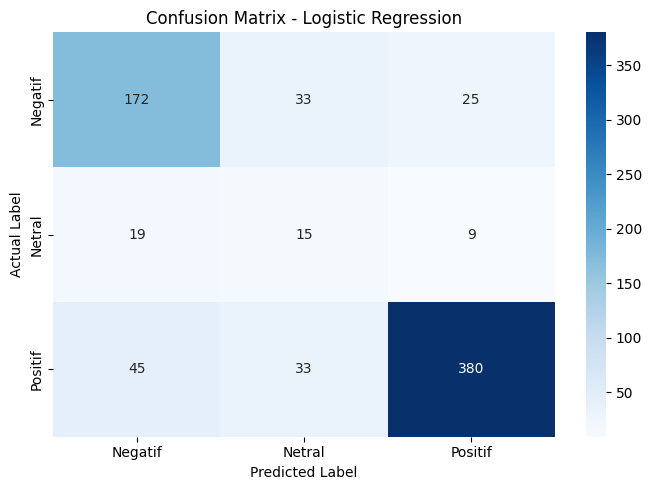

In [52]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred_best,
    labels=[-1, 0, 1]
)

plt.figure(figsize=(7, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=['Negatif', 'Netral', 'Positif'],
    yticklabels=['Negatif', 'Netral', 'Positif']
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('Actual Label')
plt.tight_layout()
plt.show()